# 03 · Signals

All signals are evaluated at the close of day *t* using information available then, and ranked
**within segment** so the book never bets on one segment against another.

| Signal | Definition | Data |
|---|---|---|
| Value | book equity / market cap (as-traded price x shares) | SEC XBRL, entered the day after filing |
| Strength | equity / total assets | SEC XBRL |
| Freight-beta momentum | rolling freight beta x 63-day change in the segment freight index | Baltic indices |
| Residual | 10/20-day cumulative return unexplained by freight + market, z-scored | Baltic indices, SPY |

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from shiplab import research, style
inp = research.Inputs()
z_v, z_s, z_f = research.factor_z(inp)
fwd = inp.tr.shift(-1).rolling(21).sum().shift(-20)   # next-month return
def ic(z, name):
    rows = []
    for s in sorted(inp.seg.unique()):
        cols = [c for c in z.columns if inp.seg[c] == s]
        m = z[cols].resample("ME").last(); f = fwd[cols].reindex(m.index)
        ok = m.notna().sum(axis=1) >= 4                      # months with 4+ ranked names
        x = m[ok].corrwith(f[ok], axis=1, method="spearman").loc["2011":"2022"].dropna()
        rows.append({"signal": name, "segment": s, "mean_IC": x.mean(), "months": len(x),
                     "t_stat": x.mean() / x.std() * np.sqrt(len(x)) if len(x) > 2 else np.nan})
    return rows
ic_tab = pd.DataFrame(ic(z_v, "value") + ic(z_s, "strength") + ic(z_f, "freight_beta_momentum"))
ics = ic_tab.pivot(index="segment", columns="signal", values="mean_IC")
ic_tab.round(3)

,signal,segment,mean_IC,months,t_stat
0,value,containers,-0.025,16,-0.152
1,value,dry_bulk,0.138,47,1.571
2,value,gas,0.043,74,0.705
3,value,tankers,0.025,71,0.464
4,strength,containers,-0.237,19,-2.148
5,strength,dry_bulk,0.153,47,2.082
6,strength,gas,-0.015,79,-0.275
7,strength,tankers,0.014,83,0.309
8,freight_beta_momentum,containers,-0.003,19,-0.026
9,freight_beta_momentum,dry_bulk,0.029,46,0.352


Average monthly rank correlation (information coefficient) between each signal and the next
month's return, within segment, 2011-2022, using only months with at least four ranked names.
With 4-10 names per segment, monthly ICs are noisy: read the t-statistic, not the size. Values of
0.03-0.05 with |t| above 2 would be typical of a tradable equity signal.

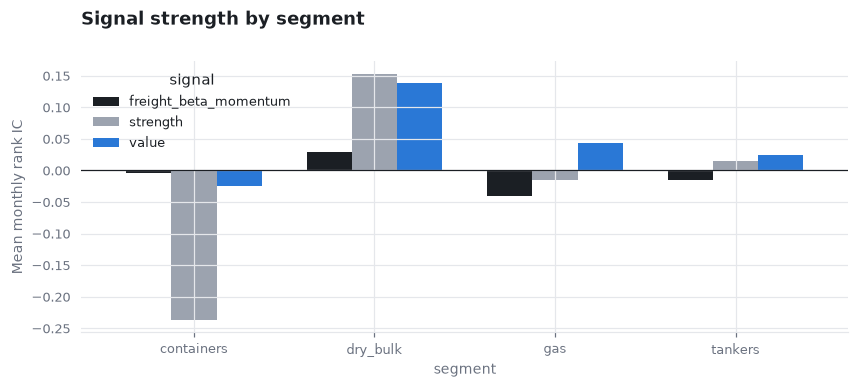

In [2]:
style.apply()
fig, ax = plt.subplots(figsize=(9, 3.2))
ics.plot.bar(ax=ax, color=[style.INK, "#9CA3AF", style.SEGMENT_COLORS["tankers"]], width=0.75)
ax.axhline(0, color=style.INK, lw=0.8); ax.set_ylabel("Mean monthly rank IC")
ax.set_title("Signal strength by segment"); ax.tick_params(axis="x", rotation=0)
plt.show()